# 04 v2 KG-guided knowledge transfer: training and evaluation

**What changed from v1.** v1 trained on seen diseases and lost the zero-shot ability of MONET (unseen BAcc fell from 43% to 27%), and the graph added nothing over text. v2 fixes the protocol and makes the graph the transfer mechanism:

1. **Pseudo-unseen validation.** 20% of the seen diseases are held out entirely and used to choose the epoch, the ensemble weight and the GZSL calibration. No test class is ever used for model selection.
2. **Stay close to MONET.** Each disease classifier is its MONET text embedding plus a residual $\Delta_d$ with an L2 penalty; at inference the trained scores are ensembled with MONET zero-shot scores (weight $\alpha$ chosen on validation).
3. **Knowledge transfer over the KG.** Unseen diseases have no images, so their residual is propagated from seen diseases through the graph:
$$\hat\Delta_u = g\sum_{s} a_{us}\,\Delta_s,\qquad a_{us}=\operatorname{softmax}_s\Big(\tfrac{1}{\tau}\sum_r \operatorname{softplus}(\beta_r)\,P_r[u,s]\Big)$$
$P_r$ is a disease-disease affinity per relation type (shared morphology, color, location, ..., taxonomy, differential diagnosis, subtype, similarity). The relation weights $\beta_r$ are learned **episodically**: in every batch a random 20% of the training diseases pretend to be unseen and must be recognised with propagated residuals only. The learned $\beta_r$ show which kind of knowledge transfers.
4. **Long-tail.** Each class mixes its own residual with the propagated one, $\Delta_c' = (1-\rho_c)\Delta_c + \rho_c\hat\Delta_c$ with $\rho_c = k/(k+n_c)$: rare diseases lean on their KG neighbours.

Every baseline gets the same validation, ensembling and calibration, so differences come from the transfer mechanism. Results go to `results_v2b/`, figures to `figures_v2b/` (one per cell, PDF + PNG). Runs are resumable.

In [1]:
# ============ Config ============
from pathlib import Path

DATA = Path('data_v2'); FEAT = DATA / 'features'; KG = DATA / 'kg'
RES  = Path('results_v2b'); FIG = Path('figures_v2b')

BACKBONE, TEXT_VIEW, OURS = 'monet', 'full_text', 'Ours'

LOGIT_SCALE = 30.0      # initial scale of the trained cosine classifier
ZS_SCALE    = 100.0     # MONET's own logit scale for zero-shot scores
LAMBDA      = 0.1       # L2 penalty on residuals (keeps classifiers close to MONET text)
MASK_FRAC   = 0.2       # episodic pseudo-unseen fraction per batch
VAL_FRAC    = 0.2       # seen diseases held out as pseudo-unseen validation
EPOCHS, BATCH, LR = 30, 512, 5e-3
ALPHAS      = [0.0, 0.25, 0.5, 0.75, 1.0]   # ensemble weight of MONET zero-shot
SHRINK_K    = [0, 5, 20, 50, 100]           # long-tail shrinkage toward KG neighbours

N_SPLITS, UNSEEN_FRAC, LT_SEEDS = 5, 0.20, [0, 1, 2]
ZSL_METHODS = ['zs_name', 'zs_full', 'residual', 'uniform', 'ours', 'ours_shuffled']
LT_METHODS  = ['zs_full', 'lp', 'lp_la', 'residual_la', 'ours_la']
ABLATION    = True
N_CASES     = 3

QUICK, FORCE = False, False
if QUICK:
    N_SPLITS, LT_SEEDS, EPOCHS = 2, [0], 8
    RES = Path('results_v2b_quick')
for d in (RES, RES / 'models', FIG):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
import json, math, time, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.path import Path as MPath
from matplotlib.patches import PathPatch, Patch
from matplotlib.lines import Line2D
from PIL import Image
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight', 'savefig.dpi': 300})
PAL = {'zs_name': '#bdbdbd', 'zs_full': '#8c8c8c', 'residual': '#1f78b4', 'uniform': '#a6cee3',
       'ours': '#c1121f', 'ours_shuffled': '#e9c46a', 'lp': '#b2df8a', 'lp_la': '#33a02c',
       'residual_la': '#1f78b4', 'ours_la': '#c1121f'}
NAMES = {'zs_name': 'MONET zero-shot (name)', 'zs_full': 'MONET zero-shot (KG text)',
         'residual': 'Residual tuning (no KG)', 'uniform': 'Uniform transfer (no KG)',
         'ours': OURS, 'ours_shuffled': f'{OURS}, shuffled KG', 'lp': 'Linear probe',
         'lp_la': 'Linear probe + LA', 'residual_la': 'Residual tuning + LA', 'ours_la': f'{OURS} + LA'}
TYPE_COL = {'Morphology': '#2a6f97', 'SecondaryChange': '#61a5c2', 'Color': '#f4a261',
            'Configuration': '#2a9d8f', 'Location': '#8ab17d', 'Etiology': '#e9c46a', 'Symptom': '#bc6c25',
            'Category': '#6a4c93', 'SuperCategory': '#3d348b'}

def savefig(fig, name):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG / f'{name}.{ext}')
    print('saved', FIG / f'{name}.pdf')
print('device:', DEVICE)

c:\Users\78479\anaconda3\envs\skin311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda


## 1. Data

In [3]:
meta = pd.read_csv(DATA / 'meta.csv')
tax  = pd.read_csv(DATA / 'taxonomy.csv').sort_values('disease_id').reset_index(drop=True)
Cn, y = len(tax), meta['disease_id'].to_numpy()
dname, cat_of = tax['disease'].to_numpy(), tax['category'].to_numpy()

X  = np.load(FEAT / BACKBONE / 'image.npy').astype(np.float32)
T  = np.load(FEAT / BACKBONE / f'text_{TEXT_VIEW}.npy').astype(np.float32)
Tn = np.load(FEAT / BACKBONE / 'text_name_text.npy').astype(np.float32)
assert X.shape[1] == T.shape[1], 'v2 needs a vision-language backbone (image and text in one space)'
D = X.shape[1]
Xt = F.normalize(torch.from_numpy(X), dim=-1).to(DEVICE)
Tt = F.normalize(torch.from_numpy(T), dim=-1).to(DEVICE)
LZ      = (ZS_SCALE * Xt @ Tt.T).cpu()                                            # zero-shot logits, KG text
LZ_name = (ZS_SCALE * Xt @ F.normalize(torch.from_numpy(Tn), dim=-1).to(DEVICE).T).cpu()

nodes, edges = pd.read_csv(KG / 'nodes.csv'), pd.read_csv(KG / 'edges.csv')
ntype = dict(zip(nodes['node_id'], nodes['type']))
img_path = meta['cache_path'].where(meta['cache_path'].notna(), meta['path']).to_numpy()
split_lt = meta['split_lt'].to_numpy()
n_train = np.bincount(y[split_lt == 'train'], minlength=Cn)
print(f'{len(meta)} images | {Cn} diseases | dim {D}')

16321 images | 114 diseases | dim 768


## 2. Relation-specific disease affinities $P_r$

In [4]:
ATTR_MAP = {'HAS_MORPHOLOGY': 'morphology', 'HAS_SECONDARY': 'secondary change', 'HAS_COLOR': 'color',
            'HAS_CONFIGURATION': 'configuration', 'LOCATED_AT': 'location', 'HAS_ETIOLOGY': 'etiology',
            'HAS_SYMPTOM': 'symptom'}
REL_KEYS = list(ATTR_MAP.values()) + ['taxonomy', 'differential', 'subtype', 'similar']
GROUPS = {k: [k] for k in ATTR_MAP.values()}
GROUPS.update({'taxonomy': ['taxonomy'], 'disease-disease': ['differential', 'subtype', 'similar']})
DIS = {'Disease:' + d: i for i, d in enumerate(dname)}

def relation_mats(e):
    P = {}
    for rel, key in ATTR_MAP.items():                 # shared attributes, IDF-weighted cosine
        g = e[(e['relation'] == rel) & e['head'].isin(DIS)]
        attrs = sorted(g['tail'].unique()); ai = {a: j for j, a in enumerate(attrs)}
        B = np.zeros((Cn, max(len(attrs), 1)))
        B[g['head'].map(DIS).to_numpy(), g['tail'].map(ai).to_numpy()] = 1
        Bw = B * (np.log((1 + Cn) / (1 + B.sum(0))) + 1)
        Z = Bw / np.maximum(np.linalg.norm(Bw, axis=1, keepdims=True), 1e-8)
        P[key] = Z @ Z.T
    g = e[(e['relation'] == 'BELONGS_TO') & e['head'].isin(DIS)]
    cat = pd.Series(g['tail'].to_numpy(), index=g['head'].map(DIS)).reindex(range(Cn)).to_numpy()
    P['taxonomy'] = (cat[:, None] == cat[None, :]).astype(float)
    for rel, key in (('DIFFERENTIAL_OF', 'differential'), ('SUBTYPE_OF', 'subtype'), ('SIMILAR_TO', 'similar')):
        g = e[(e['relation'] == rel) & e['head'].isin(DIS) & e['tail'].isin(DIS)]
        M = np.zeros((Cn, Cn)); M[g['head'].map(DIS), g['tail'].map(DIS)] = g['weight'].to_numpy()
        P[key] = np.maximum(M, M.T)
    out = np.stack([P[k] for k in REL_KEYS]).astype(np.float32)
    out[:, np.arange(Cn), np.arange(Cn)] = 0
    return out

def shuffled_edges(e, seed):
    # type-preserving rewiring: permute tails within each relation (keeps degrees and node types)
    rng = np.random.default_rng(seed); out = e.copy()
    for _, g in out.groupby('relation'):
        out.loc[g.index, 'tail'] = rng.permutation(g['tail'].to_numpy())
    return out

P_FULL = relation_mats(edges)
P_UNIFORM = np.ones((1, Cn, Cn), dtype=np.float32)
def P_without(group):
    P = P_FULL.copy(); P[[REL_KEYS.index(k) for k in GROUPS[group]]] = 0; return P
print('relations:', REL_KEYS)
print('mean affinity per relation:', dict(zip(REL_KEYS, P_FULL.mean((1, 2)).round(3))))

relations: ['morphology', 'secondary change', 'color', 'configuration', 'location', 'etiology', 'symptom', 'taxonomy', 'differential', 'subtype', 'similar']
mean affinity per relation: {'morphology': np.float32(0.234), 'secondary change': np.float32(0.075), 'color': np.float32(0.226), 'configuration': np.float32(0.115), 'location': np.float32(0.171), 'etiology': np.float32(0.094), 'symptom': np.float32(0.345), 'taxonomy': np.float32(0.387), 'differential': np.float32(0.032), 'subtype': np.float32(0.001), 'similar': np.float32(0.023)}


## 3. Models

In [5]:
class Transfer(nn.Module):
    # classifier of disease d = MONET text embedding t_d + residual; unseen residuals come from the KG
    def __init__(self, P):
        super().__init__()
        self.register_buffer('P', torch.as_tensor(P, device=DEVICE))
        self.delta = nn.Parameter(torch.zeros(Cn, D))
        self.beta = nn.Parameter(torch.zeros(len(P)))
        self.log_tau = nn.Parameter(torch.tensor(math.log(0.1)))
        self.gate = nn.Parameter(torch.tensor(0.0))
        self.log_scale = nn.Parameter(torch.tensor(math.log(LOGIT_SCALE)))

    def transfer_matrix(self, sources):
        E = torch.einsum('r,rij->ij', F.softplus(self.beta), self.P) / self.log_tau.exp()
        E = E.masked_fill(~sources[None, :], float('-inf'))
        E = E.masked_fill(torch.eye(Cn, dtype=torch.bool, device=E.device), float('-inf'))
        return torch.nan_to_num(torch.softmax(E, 1))

    def weights(self, own, sources=None, rho=None):
        prop = 0 * self.delta if sources is None else torch.sigmoid(self.gate) * self.transfer_matrix(sources) @ self.delta
        if rho is not None:
            d = (1 - rho)[:, None] * self.delta + rho[:, None] * prop
        else:
            d = torch.where(own[:, None], self.delta, prop)
        return Tt + d

    def logits(self, x, W):
        return self.log_scale.exp().clamp(max=100) * x @ F.normalize(W, dim=-1).T

class Probe(nn.Module):        # linear probe baseline (cosine classifier)
    def __init__(self):
        super().__init__()
        self.W = nn.Parameter(torch.randn(Cn, D) * 0.02)
        self.log_scale = nn.Parameter(torch.tensor(math.log(LOGIT_SCALE)))
    def logits(self, x):
        return self.log_scale.exp().clamp(max=100) * x @ F.normalize(self.W, dim=-1).T

def cmask(cls):
    m = torch.zeros(Cn, dtype=torch.bool, device=DEVICE); m[torch.as_tensor(np.asarray(cls), device=DEVICE)] = True
    return m

def run_epochs(model, tr, train_cls, epochs, mode, seed, la=False, on_epoch=None):
    # mode: residual (no transfer) | transfer (episodic pseudo-unseen) | probe
    model = model.to(DEVICE)
    gen = torch.Generator().manual_seed(seed); torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0)
    tmask = cmask(train_cls); neg = torch.where(tmask, 0.0, float('-inf'))
    tc = torch.as_tensor(np.asarray(train_cls), device=DEVICE)
    prior = 0
    if la:
        cnt = np.bincount(y[tr], minlength=Cn) + 1
        prior = torch.log(torch.tensor(cnt / cnt.sum(), dtype=torch.float32, device=DEVICE))
    Xtr, ytr = Xt[tr], torch.as_tensor(y[tr], device=DEVICE)
    for ep in range(epochs):
        for b in torch.randperm(len(tr), generator=gen).to(DEVICE).split(BATCH):
            if mode == 'probe':
                L = model.logits(Xtr[b]); reg = 0
            else:
                if mode == 'transfer':
                    m = tc[torch.randperm(len(tc), generator=gen)[:max(1, int(MASK_FRAC * len(tc)))].to(DEVICE)]
                    own = tmask.clone(); own[m] = False
                    W = model.weights(own, sources=own)
                else:
                    W = model.weights(tmask)
                L = model.logits(Xtr[b], W)
                reg = LAMBDA * model.delta[tc].pow(2).sum(1).mean()
            loss = F.cross_entropy(L + neg + prior, ytr[b]) + reg
            opt.zero_grad(); loss.backward(); opt.step()
        if on_epoch is not None:
            with torch.no_grad():
                on_epoch(model, ep)
    return model

## 4. Metrics

In [6]:
def bacc(pred, yt):
    return float(np.mean([(pred[yt == c] == c).mean() for c in np.unique(yt)])) if len(yt) else float('nan')

def combine(Lt, Lz, cls, a):
    cls = torch.as_tensor(np.asarray(cls))
    return (1 - a) * torch.log_softmax(Lt[:, cls], 1) + a * torch.log_softmax(Lz[:, cls], 1)

def gzsl(G, yt, seen, allc, gamma):
    G = G.clone(); G[:, torch.as_tensor(np.searchsorted(allc, seen))] -= gamma
    p = allc[G.argmax(1).numpy()]; s = np.isin(yt, seen)
    a_s, a_u = bacc(p[s], yt[s]), bacc(p[~s], yt[~s])
    return a_s, a_u, (2 * a_s * a_u / (a_s + a_u) if a_s + a_u > 0 else 0.0)

def calibrate(G, yt, seen, allc):
    R = float(G.max() - G.min())
    return max(np.linspace(-R, R, 101), key=lambda g: gzsl(G, yt, seen, allc, g)[2])

def ausuc(G, yt, seen, allc):
    R = float(G.max() - G.min())
    pts = sorted({gzsl(G, yt, seen, allc, g)[:2] for g in np.linspace(-R, R, 101)}, key=lambda t: t[1])
    xs = np.array([0.0] + [p[1] for p in pts]); ys = np.array([max(p[0] for p in pts)] + [p[0] for p in pts])
    trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
    return float(trap(ys, xs)), pts

def per_class(pred, yt):
    return {int(c): float((pred[yt == c] == c).mean()) for c in np.unique(yt)}

BINS = meta.groupby('disease_id')['freq_bin'].first()
def eval_lt(S, idx):
    yt = y[idx]; top = np.argsort(-S, 1)[:, :5]; p = top[:, 0]; pc = per_class(p, yt)
    out = dict(top1=float((p == yt).mean()), top5=float((top == yt[:, None]).any(1).mean()),
               bacc=float(np.mean(list(pc.values()))), macro_f1=float(f1_score(yt, p, average='macro')))
    for b in ('head', 'medium', 'tail'):
        out[b] = float(np.mean([a for c, a in pc.items() if BINS.get(c) == b] or [np.nan]))
    sg = meta['skin_group'].to_numpy()[idx]
    for g in ('I-II', 'III-IV', 'V-VI'):
        out[f'skin_{g}'] = bacc(p[sg == g], yt[sg == g])
    return out

## 5. Splits

In [7]:
def zsl_split(k):
    if k == 0:
        unseen = np.sort(meta.loc[meta['unseen'], 'disease_id'].unique())
    else:
        rng = np.random.default_rng(1000 + k); unseen = []
        for _, g in tax.groupby('category'):
            n = len(g); m = min(max(int(round(UNSEEN_FRAC * n)), 1 if n >= 3 else 0), n - 1)
            unseen += rng.choice(g['disease_id'].to_numpy(), m, replace=False).tolist()
        unseen = np.sort(unseen)
    seen = np.setdiff1d(np.arange(Cn), unseen)
    s_val = np.sort(np.random.default_rng(2000 + k).choice(seen, max(2, int(round(VAL_FRAC * len(seen)))), replace=False))
    s_tr = np.setdiff1d(seen, s_val)
    I = lambda cond: np.where(cond)[0]
    return dict(k=k, unseen=unseen, seen=seen, s_tr=s_tr, s_val=s_val,
                tr1=I(np.isin(y, s_tr) & (split_lt == 'train')),                    # stage 1: model selection
                va_s=I(np.isin(y, s_tr) & (split_lt == 'val')),
                va_u=I(np.isin(y, s_val) & (split_lt != 'test')),
                tr2=I(np.isin(y, seen) & (split_lt == 'train')),                     # stage 2: final model
                te_s=I(np.isin(y, seen) & (split_lt == 'test')), te_u=I(np.isin(y, unseen)))

SPLITS = [zsl_split(k) for k in range(N_SPLITS)]
LT = {s: np.where(split_lt == s)[0] for s in ('train', 'val', 'test')}
for sp in SPLITS:
    print(f"split {sp['k']}: unseen {len(sp['unseen'])} | val-unseen {len(sp['s_val'])} | train-seen {len(sp['s_tr'])}")

split 0: unseen 23 | val-unseen 18 | train-seen 73
split 1: unseen 23 | val-unseen 18 | train-seen 73
split 2: unseen 23 | val-unseen 18 | train-seen 73
split 3: unseen 23 | val-unseen 18 | train-seen 73
split 4: unseen 23 | val-unseen 18 | train-seen 73


## 6. ZSL / GZSL protocol

In [8]:
METHOD_P = {'residual': (None, 'residual'), 'uniform': ('uniform', 'transfer'), 'ours': ('full', 'transfer'),
            'ours_shuffled': ('shuffled', 'transfer')}

def get_P(kind, k):
    if kind == 'full': return P_FULL
    if kind == 'uniform': return P_UNIFORM
    if kind == 'shuffled': return relation_mats(shuffled_edges(edges, 500 + k))
    return P_without(kind[4:])                                  # 'abl:<group>'

def zsl_run(sp, m):
    seed = sp['k']
    if m.startswith('zs_'):                                      # no training; calibration on validation
        LZm = LZ_name if m == 'zs_name' else LZ
        Lt, a, ep = LZm, 0.0, -1
        val_all = np.concatenate([sp['va_s'], sp['va_u']]); allv = np.sort(np.concatenate([sp['s_tr'], sp['s_val']]))
        gamma = calibrate(combine(Lt[val_all], LZm[val_all], allv, 0.0), y[val_all], sp['s_tr'], allv)
        Lt_u, Lt_g, LZ_use, model = Lt[sp['te_u']], Lt[np.concatenate([sp['te_s'], sp['te_u']])], LZm, None
    else:
        Pkind, mode = METHOD_P.get(m, (m, 'transfer'))
        P = get_P(Pkind, sp['k']) if Pkind else P_UNIFORM
        # ---- stage 1: choose epoch and alpha on pseudo-unseen validation diseases ----
        best = dict(h=-1)
        own_v = cmask(sp['s_tr'])
        def on_epoch(model, ep):
            W = model.weights(own_v, sources=None if mode == 'residual' else own_v)
            Ls, Lu = model.logits(Xt[sp['va_s']], W).cpu(), model.logits(Xt[sp['va_u']], W).cpu()
            for a in ALPHAS:
                bs = bacc(sp['s_tr'][combine(Ls, LZ[sp['va_s']], sp['s_tr'], a).argmax(1).numpy()], y[sp['va_s']])
                bu = bacc(sp['s_val'][combine(Lu, LZ[sp['va_u']], sp['s_val'], a).argmax(1).numpy()], y[sp['va_u']])
                h = 2 * bs * bu / (bs + bu) if bs + bu > 0 else 0
                if h > best['h']:
                    best.update(h=h, ep=ep, a=a, bs=bs, bu=bu, state=copy.deepcopy(model.state_dict()))
        model = run_epochs(Transfer(P), sp['tr1'], sp['s_tr'], EPOCHS, mode, seed, on_epoch=on_epoch)
        model.load_state_dict(best['state'])
        a, ep = best['a'], best['ep']
        with torch.no_grad():                                    # GZSL calibration on validation
            W = model.weights(own_v, sources=None if mode == 'residual' else own_v)
            val_all = np.concatenate([sp['va_s'], sp['va_u']]); allv = np.sort(np.concatenate([sp['s_tr'], sp['s_val']]))
            G = combine(model.logits(Xt[val_all], W).cpu(), LZ[val_all], allv, a)
            gamma = calibrate(G, y[val_all], sp['s_tr'], allv)
        # ---- stage 2: retrain on all seen diseases with the chosen epochs ----
        model = run_epochs(Transfer(P), sp['tr2'], sp['seen'], ep + 1, mode, seed)
        with torch.no_grad():
            own = cmask(sp['seen'])
            W = model.weights(own, sources=None if mode == 'residual' else own)
            Lt_u = model.logits(Xt[sp['te_u']], W).cpu()
            Lt_g = model.logits(Xt[np.concatenate([sp['te_s'], sp['te_u']])], W).cpu()
        LZ_use = LZ
    te_g = np.concatenate([sp['te_s'], sp['te_u']]); allc = np.arange(Cn)
    pu = sp['unseen'][combine(Lt_u, LZ_use[sp['te_u']], sp['unseen'], a).argmax(1).numpy()]
    G = combine(Lt_g, LZ_use[te_g], allc, a)
    s_c, u_c, h_c = gzsl(G, y[te_g], sp['seen'], allc, gamma)
    _, _, h_0 = gzsl(G, y[te_g], sp['seen'], allc, 0.0)
    au, curve = ausuc(G, y[te_g], sp['seen'], allc)
    rec = dict(zsl_bacc=bacc(pu, y[sp['te_u']]), gzsl_s=s_c, gzsl_u=u_c, gzsl_h=h_c, gzsl_h_uncal=h_0, ausuc=au,
               alpha=a, epochs=ep + 1, gamma=float(gamma), per_class_unseen=per_class(pu, y[sp['te_u']]), curve=curve)
    if model is not None:
        rec.update(beta=F.softplus(model.beta).tolist(), tau=float(model.log_tau.exp()),
                   gate=float(torch.sigmoid(model.gate)))
    return rec, model

## 7. Long-tail protocol

In [9]:
def lt_run(seed, m):
    if m == 'zs_full':
        return eval_lt(torch.log_softmax(LZ[LT['test']], 1).numpy(), LT['test'])
    allc = np.arange(Cn); la = m.endswith('_la'); best = dict(b=-1)
    if m.startswith('lp'):
        def on_epoch(model, ep):
            b = bacc(model.logits(Xt[LT['val']]).argmax(1).cpu().numpy(), y[LT['val']])
            if b > best['b']:
                best.update(b=b, state=copy.deepcopy(model.state_dict()))
        model = run_epochs(Probe().to(DEVICE), LT['train'], allc, EPOCHS, 'probe', seed, la=la, on_epoch=on_epoch)
        model.load_state_dict(best['state'])
        with torch.no_grad():
            return eval_lt(model.logits(Xt[LT['test']]).cpu().numpy(), LT['test'])
    mode = 'residual' if m.startswith('residual') else 'transfer'
    every = cmask(allc); n = torch.tensor(n_train, dtype=torch.float32, device=DEVICE)
    ks = [0] if mode == 'residual' else SHRINK_K
    def W_of(model, k):
        return model.weights(every, sources=None if mode == 'residual' else every, rho=k / (k + n))
    def on_epoch(model, ep):
        for k in ks:
            Lv = model.logits(Xt[LT['val']], W_of(model, k)).cpu()
            for a in ALPHAS:
                b = bacc(combine(Lv, LZ[LT['val']], allc, a).argmax(1).numpy(), y[LT['val']])
                if b > best['b']:
                    best.update(b=b, k=k, a=a, state=copy.deepcopy(model.state_dict()))
    model = run_epochs(Transfer(P_FULL), LT['train'], allc, EPOCHS, mode, seed, la=la, on_epoch=on_epoch)
    model.load_state_dict(best['state'])
    with torch.no_grad():
        S = combine(model.logits(Xt[LT['test']], W_of(model, best['k'])).cpu(), LZ[LT['test']], allc, best['a'])
    return dict(eval_lt(S.numpy(), LT['test']), k=best['k'], alpha=best['a'])

## 8. Run everything (resumable)

In [10]:
RUNS = RES / 'runs.jsonl'
def load_runs():
    return [json.loads(l) for l in open(RUNS)] if RUNS.exists() else []
done = set() if FORCE else {r['key'] for r in load_runs()}
def record(rec):
    with open(RUNS, 'a') as fh:
        fh.write(json.dumps(rec) + '\n')
    done.add(rec['key'])

jobs = [('zsl', sp, m) for sp in SPLITS for m in ZSL_METHODS]
if ABLATION:
    jobs += [('zsl', sp, 'abl:' + g) for sp in SPLITS for g in GROUPS]
jobs += [('lt', s, m) for s in LT_SEEDS for m in LT_METHODS if not (m == 'zs_full' and s != LT_SEEDS[0])]

for setting, x, m in tqdm(jobs):
    key = f"zsl|{m}|{x['k']}" if setting == 'zsl' else f'lt|{m}|{x}'
    if key in done:
        continue
    t0 = time.time()
    if setting == 'zsl':
        rec, model = zsl_run(x, m)
        if m == 'ours' and model is not None:
            torch.save(model.state_dict(), RES / 'models' / f"zsl_ours_{x['k']}.pt")
        record(dict(key=key, setting='zsl', method=m, split=x['k'], secs=round(time.time() - t0, 1), **rec))
    else:
        record(dict(key=key, setting='lt', method=m, seed=x, secs=round(time.time() - t0, 1), **lt_run(x, m)))
print('finished runs:', len(done))

  0%|          | 0/88 [00:00<?, ?it/s]C:\Users\78479\AppData\Local\Temp\ipykernel_11808\3908839046.py:58: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  rec.update(beta=F.softplus(model.beta).tolist(), tau=float(model.log_tau.exp()),
100%|██████████| 88/88 [04:02<00:00,  2.75s/it]

finished runs: 88


## 9. Tables

In [11]:
runs = pd.DataFrame(load_runs())
Z, LTR = runs[runs['setting'] == 'zsl'], runs[runs['setting'] == 'lt']

def ms(s):
    v = s.dropna().to_numpy() * 100
    return f'{v.mean():.1f} $\\pm$ {v.std():.1f}' if len(v) > 1 else f'{v.mean():.1f}'

def latex(df, methods, cols, heads, caption, label, bold=('ours', 'ours_la')):
    L = ['\\begin{table}[t]', '\\centering', f'\\caption{{{caption}}}', f'\\label{{{label}}}',
         '\\resizebox{\\columnwidth}{!}{%', '\\begin{tabular}{l' + 'c' * len(cols) + '}', '\\toprule',
         'Method & ' + ' & '.join(heads) + ' \\\\', '\\midrule']
    for m in methods:
        g = df[df['method'] == m]
        if len(g):
            nm = NAMES.get(m, m)
            L.append((f'\\textbf{{{nm}}}' if m in bold else nm) + ' & ' + ' & '.join(ms(g[c]) for c in cols) + ' \\\\')
    return '\n'.join(L + ['\\bottomrule', '\\end{tabular}}', '\\end{table}'])

zc = ['zsl_bacc', 'gzsl_s', 'gzsl_u', 'gzsl_h', 'ausuc']
lc = ['top1', 'bacc', 'macro_f1', 'head', 'medium', 'tail']
tex = [latex(Z, ZSL_METHODS, zc, ['ZSL BAcc', 'GZSL $S$', 'GZSL $U$', '$H$', 'AUSUC'],
             f'Zero-shot and generalized zero-shot recognition of unseen diseases (mean $\\pm$ std over {N_SPLITS} splits). '
             'All methods share the same validation, ensembling and calibration protocol.', 'tab:zsl'),
       latex(LTR, LT_METHODS, lc, ['Top-1', 'BAcc', 'Macro-F1', 'Head', 'Medium', 'Tail'],
             f'Long-tailed recognition on the closed-set split (mean $\\pm$ std over {len(LT_SEEDS)} seeds).', 'tab:lt')]
if ABLATION:
    A = Z[Z['method'].str.startswith('abl:') | (Z['method'] == 'ours')].copy()
    A['method'] = A['method'].str.replace('abl:', 'w/o ', regex=False)
    tex.append(latex(A, ['ours'] + ['w/o ' + g for g in GROUPS], ['zsl_bacc', 'gzsl_h'], ['ZSL BAcc', '$H$'],
                     'Leave-one-relation-group-out ablation on unseen diseases.', 'tab:ablation'))
open(RES / 'tables.tex', 'w').write('\n\n'.join(tex))
print('\n\n'.join(tex))
print('\nselected ensemble weight alpha (mean over splits):')
print(Z[Z['method'].isin(ZSL_METHODS)].groupby('method')['alpha'].mean().round(2).to_string())

\begin{table}[t]
\centering
\caption{Zero-shot and generalized zero-shot recognition of unseen diseases (mean $\pm$ std over 5 splits). All methods share the same validation, ensembling and calibration protocol.}
\label{tab:zsl}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{lccccc}
\toprule
Method & ZSL BAcc & GZSL $S$ & GZSL $U$ & $H$ & AUSUC \\
\midrule
MONET zero-shot (name) & 41.5 $\pm$ 2.8 & 14.4 $\pm$ 2.1 & 31.7 $\pm$ 4.8 & 19.4 $\pm$ 1.1 & 7.1 $\pm$ 0.3 \\
MONET zero-shot (KG text) & 43.1 $\pm$ 2.5 & 16.6 $\pm$ 1.6 & 29.7 $\pm$ 2.3 & 21.2 $\pm$ 0.8 & 7.6 $\pm$ 0.4 \\
Residual tuning (no KG) & 43.1 $\pm$ 2.5 & 32.6 $\pm$ 3.7 & 34.4 $\pm$ 2.4 & 33.2 $\pm$ 1.5 & 17.2 $\pm$ 0.8 \\
Uniform transfer (no KG) & 43.0 $\pm$ 2.2 & 32.6 $\pm$ 3.4 & 33.9 $\pm$ 1.1 & 33.1 $\pm$ 1.4 & 16.6 $\pm$ 0.9 \\
\textbf{Ours} & 43.4 $\pm$ 2.6 & 33.0 $\pm$ 2.0 & 33.1 $\pm$ 1.3 & 33.0 $\pm$ 1.2 & 16.5 $\pm$ 0.8 \\
Ours, shuffled KG & 40.8 $\pm$ 2.5 & 32.9 $\pm$ 3.6 & 30.1 $\pm$ 2.8 & 31.2 $\pm$ 1.6 & 15.1

## 10. Result figures (one per cell)

### Fig. 1 Zero-shot balanced accuracy on unseen diseases

saved figures_v2b\fig1_zsl_bacc.pdf


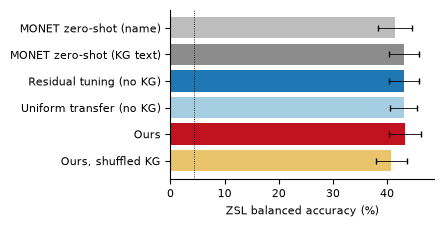

In [12]:
ms_ = [m for m in ZSL_METHODS if m in set(Z['method'])]
v = Z.groupby('method')['zsl_bacc'].agg(['mean', 'std']).reindex(ms_) * 100
fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.barh(range(len(v)), v['mean'], xerr=v['std'].fillna(0), color=[PAL[m] for m in ms_], error_kw=dict(lw=0.6, capsize=2))
ax.set_yticks(range(len(v)), [NAMES[m] for m in ms_]); ax.invert_yaxis()
ax.axvline(100 / np.mean([len(s['unseen']) for s in SPLITS]), ls=':', c='k', lw=0.6)
ax.set_xlabel('ZSL balanced accuracy (%)')
savefig(fig, 'fig1_zsl_bacc'); plt.show()

### Fig. 2 Seen-unseen trade-off (GZSL, split 0)

saved figures_v2b\fig2_gzsl_curve.pdf


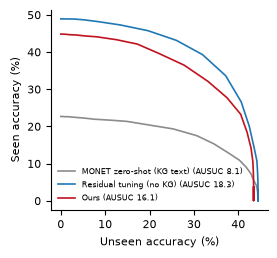

In [13]:
fig, ax = plt.subplots(figsize=(2.8, 2.6))
for m in [x for x in ('zs_full', 'residual', 'ours') if x in set(Z['method'])]:
    r = Z[(Z['method'] == m) & (Z['split'] == 0)].iloc[0]
    c = np.array(r['curve']) * 100
    ax.plot(c[:, 1], c[:, 0], c=PAL[m], lw=1.2, label=f"{NAMES[m]} (AUSUC {r['ausuc'] * 100:.1f})")
ax.set_xlabel('Unseen accuracy (%)'); ax.set_ylabel('Seen accuracy (%)'); ax.legend(fontsize=6, frameon=False)
savefig(fig, 'fig2_gzsl_curve'); plt.show()

### Fig. 3 Long-tail accuracy by frequency bin

saved figures_v2b\fig3_longtail_bins.pdf


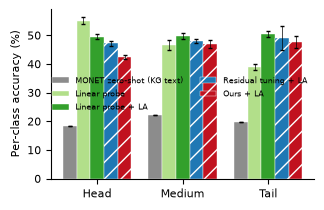

In [14]:
ms_ = [m for m in LT_METHODS if m in set(LTR['method'])]
bins = ['head', 'medium', 'tail']; w = 0.8 / len(ms_)
fig, ax = plt.subplots(figsize=(3.4, 2.2))
for i, m in enumerate(ms_):
    g = LTR[LTR['method'] == m]
    ax.bar(np.arange(3) + (i - (len(ms_) - 1) / 2) * w, g[bins].mean() * 100, w, yerr=g[bins].std().fillna(0) * 100,
           color=PAL[m], label=NAMES[m], hatch='//' if m in ('residual_la', 'ours_la') else None,
           edgecolor='w', lw=0.3, error_kw=dict(lw=0.5, capsize=1.5))
ax.set_xticks(range(3), ['Head', 'Medium', 'Tail']); ax.set_ylabel('Per-class accuracy (%)')
ax.legend(fontsize=6, frameon=False, ncol=2)
savefig(fig, 'fig3_longtail_bins'); plt.show()

### Fig. 4 Relation-group ablation

saved figures_v2b\fig4_ablation.pdf


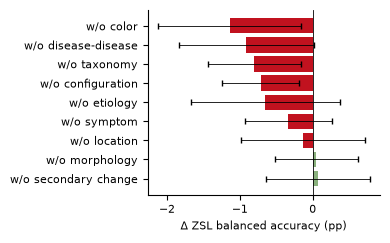

In [15]:
if ABLATION:
    full = Z[Z['method'] == 'ours'].set_index('split')['zsl_bacc']
    rows = []
    for g in GROUPS:
        a = Z[Z['method'] == 'abl:' + g].set_index('split')['zsl_bacc']
        d = (a - full.reindex(a.index)) * 100
        rows.append((g, d.mean(), d.std()))
    rows.sort(key=lambda t: t[1])
    fig, ax = plt.subplots(figsize=(3.0, 2.4))
    ax.barh(range(len(rows)), [r[1] for r in rows], xerr=[0 if np.isnan(r[2]) else r[2] for r in rows],
            color=['#c1121f' if r[1] < 0 else '#8ab17d' for r in rows], error_kw=dict(lw=0.6, capsize=2))
    ax.set_yticks(range(len(rows)), [f'w/o {r[0]}' for r in rows]); ax.invert_yaxis()
    ax.axvline(0, c='k', lw=0.6); ax.set_xlabel('$\\Delta$ ZSL balanced accuracy (pp)')
    savefig(fig, 'fig4_ablation'); plt.show()

### Fig. 5 Learned relation weights: which knowledge transfers

saved figures_v2b\fig5_relation_weights.pdf


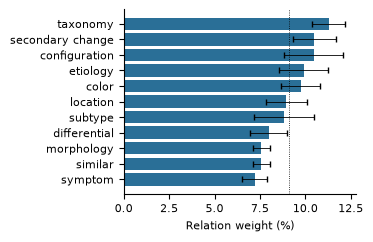

In [16]:
B = np.array(Z[Z['method'] == 'ours']['beta'].tolist())
B = B / B.sum(1, keepdims=True)
o = np.argsort(-B.mean(0))
fig, ax = plt.subplots(figsize=(3.0, 2.4))
ax.barh(range(len(o)), B.mean(0)[o] * 100, xerr=B.std(0)[o] * 100, color='#2a6f97', error_kw=dict(lw=0.6, capsize=2))
ax.set_yticks(range(len(o)), [REL_KEYS[i] for i in o]); ax.invert_yaxis()
ax.axvline(100 / len(REL_KEYS), ls=':', c='k', lw=0.6)
ax.set_xlabel('Relation weight (%)')
savefig(fig, 'fig5_relation_weights'); plt.show()

### Fig. 6 Per-class accuracy on unseen diseases: zero-shot vs. ours (all splits)

improved 50% | equal 3% | worse 47%
saved figures_v2b\fig6_unseen_per_class.pdf


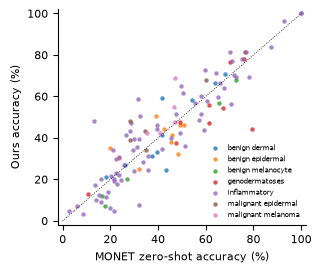

In [17]:
pts = []
for k in range(N_SPLITS):
    a = Z[(Z['method'] == 'zs_full') & (Z['split'] == k)]['per_class_unseen']
    b = Z[(Z['method'] == 'ours') & (Z['split'] == k)]['per_class_unseen']
    if len(a) and len(b):
        a, b = a.iloc[0], b.iloc[0]
        pts += [(a[c], b[c], cat_of[int(c)]) for c in a if c in b]
P_ = pd.DataFrame(pts, columns=['zs', 'ours', 'cat'])
fig, ax = plt.subplots(figsize=(3.2, 2.8)); cmap = plt.get_cmap('tab10')
for i, (c, g) in enumerate(P_.groupby('cat')):
    ax.scatter(g['zs'] * 100, g['ours'] * 100, s=10, color=cmap(i), label=c, alpha=0.8, lw=0)
ax.plot([0, 100], [0, 100], c='k', lw=0.6, ls=':')
ax.set(xlabel='MONET zero-shot accuracy (%)', ylabel=f'{OURS} accuracy (%)', xlim=(-2, 102), ylim=(-2, 102))
ax.legend(fontsize=5, frameon=False, loc='lower right')
print(f"improved {(P_.ours > P_.zs).mean():.0%} | equal {(P_.ours == P_.zs).mean():.0%} | worse {(P_.ours < P_.zs).mean():.0%}")
savefig(fig, 'fig6_unseen_per_class'); plt.show()

### Fig. 7 Long-tail balanced accuracy by Fitzpatrick skin type

saved figures_v2b\fig7_skin_type.pdf


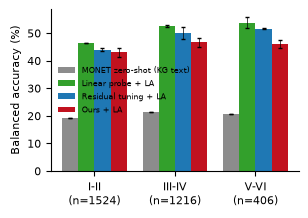

In [18]:
groups = ['I-II', 'III-IV', 'V-VI']
ms_ = [m for m in ('zs_full', 'lp_la', 'residual_la', 'ours_la') if m in set(LTR['method'])]
w = 0.8 / len(ms_)
fig, ax = plt.subplots(figsize=(3.2, 2.1))
for i, m in enumerate(ms_):
    g = LTR[LTR['method'] == m][[f'skin_{s}' for s in groups]]
    ax.bar(np.arange(3) + (i - (len(ms_) - 1) / 2) * w, g.mean() * 100, w, yerr=g.std().fillna(0) * 100,
           color=PAL[m], label=NAMES[m], error_kw=dict(lw=0.5, capsize=1.5))
n = meta.loc[LT['test'], 'skin_group'].value_counts()
ax.set_xticks(range(3), [f'{s}\n(n={n.get(s, 0)})' for s in groups])
ax.set_ylabel('Balanced accuracy (%)'); ax.legend(fontsize=6, frameon=False)
savefig(fig, 'fig7_skin_type'); plt.show()

## 11. Knowledge graph figures (one per cell)

### Fig. KG-1 Whole knowledge graph (chord layout)

saved figures_v2b\figKG1_whole_graph.pdf


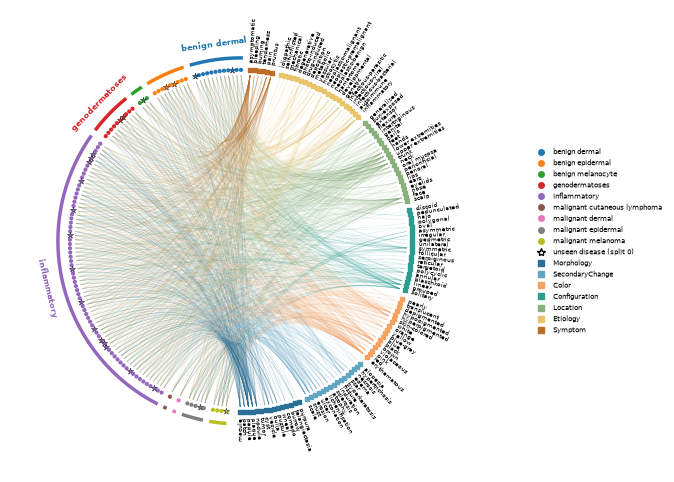

In [19]:
# diseases (grouped by category) and attribute nodes (grouped by type) on one circle; edges as curves through the centre
ATTR_TYPES = ['Morphology', 'SecondaryChange', 'Color', 'Configuration', 'Location', 'Etiology', 'Symptom']
cats = sorted(set(cat_of))
dis_order = [i for c in cats for i in np.where(cat_of == c)[0]]
attr_nodes = [n for t in ATTR_TYPES for n in nodes.loc[nodes['type'] == t, 'node_id']]
gap = 1.2                                                     # angular gap (in slots) between groups
slots, pos, cur = [], {}, 0.0
for c in cats:
    for i in np.where(cat_of == c)[0]:
        pos['Disease:' + dname[i]] = cur; cur += 1
    cur += gap
cur += gap
for t in ATTR_TYPES:
    for n in nodes.loc[nodes['type'] == t, 'node_id']:
        pos[n] = cur; cur += 1
    cur += gap
total = cur
ang = {n: 2 * np.pi * v / total + np.pi / 2 for n, v in pos.items()}
xy = {n: (np.cos(a), np.sin(a)) for n, a in ang.items()}
cmap = plt.get_cmap('tab10'); ccol = {c: cmap(i) for i, c in enumerate(cats)}
unseen0 = set(SPLITS[0]['unseen'])

fig, ax = plt.subplots(figsize=(6.0, 6.0)); ax.set_aspect('equal'); ax.axis('off')
E = edges[edges['relation'].isin(ATTR_MAP) & edges['head'].isin(xy) & edges['tail'].isin(xy)]
for h, t in E[['head', 'tail']].itertuples(index=False):
    p0, p2 = np.array(xy[h]) * 0.97, np.array(xy[t]) * 0.97
    path = MPath([p0, (p0 + p2) * 0.12, p2], [MPath.MOVETO, MPath.CURVE3, MPath.CURVE3])
    ax.add_patch(PathPatch(path, fc='none', ec=TYPE_COL[ntype[t]], lw=0.35, alpha=0.18))
for i in range(Cn):
    n = 'Disease:' + dname[i]; x, y_ = xy[n]
    ax.scatter(x, y_, s=22 if i in unseen0 else 9, color=ccol[cat_of[i]], marker='*' if i in unseen0 else 'o',
               edgecolor='k' if i in unseen0 else 'none', lw=0.3, zorder=3)
for n in attr_nodes:
    x, y_ = xy[n]; ax.scatter(x, y_, s=9, color=TYPE_COL[ntype[n]], marker='s', zorder=3)
    a = np.degrees(ang[n]); flip = 90 < (a % 360) < 270
    ax.text(1.04 * x, 1.04 * y_, n.split(':', 1)[1], fontsize=4.2, rotation=a + 180 if flip else a,
            ha='right' if flip else 'left', va='center', rotation_mode='anchor')
for c in cats:                                                # coloured arc per category; text only for large ones
    aa = np.array([ang['Disease:' + dname[i]] for i in np.where(cat_of == c)[0]])
    t = np.linspace(aa.min() - 0.01, aa.max() + 0.01, 50)
    ax.plot(1.07 * np.cos(t), 1.07 * np.sin(t), c=ccol[c], lw=2.5, solid_capstyle='butt')
    if len(aa) >= 10:
        a = aa.mean()
        ax.text(1.16 * np.cos(a), 1.16 * np.sin(a), c, fontsize=6, color=ccol[c], ha='center', va='center',
                fontweight='bold', rotation=np.degrees(a) - 90 if np.sin(a) >= 0 else np.degrees(a) + 90)
handles = [Line2D([], [], marker='o', ls='', color=ccol[c], ms=4, label=c) for c in cats]
handles += [Line2D([], [], marker='*', ls='', color='w', mec='k', ms=6, label='unseen disease (split 0)')]
handles += [Line2D([], [], marker='s', ls='', color=TYPE_COL[t], ms=4, label=t) for t in ATTR_TYPES]
ax.legend(handles=handles, fontsize=5, frameon=False, loc='center left', bbox_to_anchor=(1.12, 0.5))
ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35)
savefig(fig, 'figKG1_whole_graph'); plt.show()

### Fig. KG-2 Disease affinity per relation type (what the transfer network sees)

saved figures_v2b\figKG2_affinity_morphology.pdf


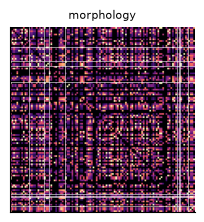

saved figures_v2b\figKG2_affinity_color.pdf


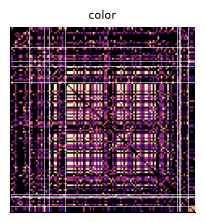

saved figures_v2b\figKG2_affinity_location.pdf


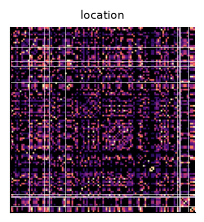

saved figures_v2b\figKG2_affinity_etiology.pdf


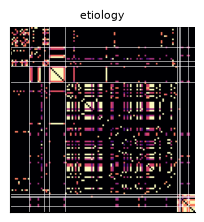

saved figures_v2b\figKG2_affinity_taxonomy.pdf


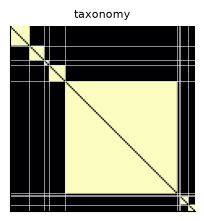

saved figures_v2b\figKG2_affinity_differential.pdf


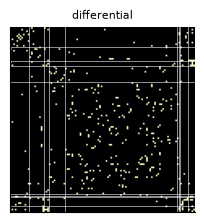

In [20]:
o = np.lexsort((dname, cat_of))
show = ['morphology', 'color', 'location', 'etiology', 'taxonomy', 'differential']
for key in show:
    M = P_FULL[REL_KEYS.index(key)][np.ix_(o, o)]
    fig, ax = plt.subplots(figsize=(2.4, 2.4))
    ax.imshow(M, cmap='magma', vmin=0, vmax=max(M.max(), 1e-6))
    cs = cat_of[o]; b = [i for i in range(1, Cn) if cs[i] != cs[i - 1]]
    for v in b:
        ax.axhline(v - .5, c='w', lw=0.4); ax.axvline(v - .5, c='w', lw=0.4)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(key, fontsize=8)
    savefig(fig, f'figKG2_affinity_{key.replace(" ", "_")}'); plt.show()

### Case studies on unseen diseases (split 0)

For each case, two figures: the **transfer subgraph** (the unseen disease, its KG attributes, and the seen diseases it borrows knowledge from, edge width = transfer weight $a_{us}$) and the **prediction panel** (image, top-3 among unseen diseases, contribution of each source disease to the score).

In [21]:
sp0 = SPLITS[0]
ours0 = Transfer(P_FULL).to(DEVICE)
ours0.load_state_dict(torch.load(RES / 'models' / 'zsl_ours_0.pt', map_location=DEVICE)); ours0.eval()
with torch.no_grad():
    own0 = cmask(sp0['seen'])
    A0 = ours0.transfer_matrix(own0).cpu().numpy()
    W0 = ours0.weights(own0, sources=own0)
    a0 = Z[(Z['method'] == 'ours') & (Z['split'] == 0)]['alpha'].iloc[0]
    Lt = ours0.logits(Xt[sp0['te_u']], W0).cpu()
u0 = sp0['unseen']; yu = y[sp0['te_u']]
Pk = torch.softmax(combine(Lt, LZ[sp0['te_u']], u0, a0), 1).numpy()
pz = u0[LZ[sp0['te_u']][:, torch.as_tensor(u0)].argmax(1).numpy()]
ok = (u0[Pk.argmax(1)] == yu) & (pz != yu)
cand = np.where(ok)[0] if ok.any() else np.where(u0[Pk.argmax(1)] == yu)[0]
cand = cand[np.argsort(-Pk[cand].max(1))]
picked, used = [], set()
for i in cand:
    if yu[i] not in used:
        picked.append(i); used.add(yu[i])
    if len(picked) == N_CASES:
        break
attr_of = {d: set(edges.loc[(edges['head'] == 'Disease:' + dname[d]) & edges['relation'].isin(ATTR_MAP), 'tail'])
           for d in range(Cn)}
print('cases:', [dname[yu[i]] for i in picked])

def transfer_subgraph(d, name, k_src=6):
    src = np.argsort(-A0[d])[:k_src]
    attrs = sorted(attr_of[d], key=lambda a: (list(TYPE_COL).index(ntype[a]), a))
    fig, ax = plt.subplots(figsize=(4.6, 3.4)); ax.set_aspect('equal'); ax.axis('off')
    pa = {a: (1.25 * np.cos(t), 1.25 * np.sin(t)) for a, t in
          zip(attrs, np.linspace(np.radians(110), np.radians(250), len(attrs)))}
    ps = {s: (1.55 * np.cos(t), 1.55 * np.sin(t)) for s, t in
          zip(src, np.linspace(np.radians(55), np.radians(-55), len(src)))}
    for s in src:                                       # shared attributes: thin grey links
        for a in attr_of[s] & attr_of[d]:
            ax.plot([ps[s][0], pa[a][0]], [ps[s][1], pa[a][1]], c='#cccccc', lw=0.4, zorder=1)
    for a in attrs:
        ax.plot([0, pa[a][0]], [0, pa[a][1]], c=TYPE_COL[ntype[a]], lw=0.8, alpha=0.7, zorder=1)
        ax.scatter(*pa[a], s=40, marker='s', color=TYPE_COL[ntype[a]], zorder=3)
        ax.text(pa[a][0] - 0.08, pa[a][1], a.split(':', 1)[1], fontsize=5.5, ha='right', va='center')
    wmax = A0[d][src].max()
    for s in src:
        ax.annotate('', xy=(0.12 * ps[s][0] / 1.55, 0.12 * ps[s][1] / 1.55), xytext=ps[s],
                    arrowprops=dict(arrowstyle='-|>', color='#c1121f', lw=0.6 + 3.5 * A0[d][s] / wmax,
                                    alpha=0.85, shrinkA=6, shrinkB=2), zorder=2)
        ax.scatter(*ps[s], s=70, color=ccol[cat_of[s]], edgecolor='k', lw=0.3, zorder=3)
        ax.text(ps[s][0] + 0.1, ps[s][1], f'{dname[s]}\n$a$={A0[d][s]:.2f}', fontsize=5.5, ha='left', va='center')
    ax.scatter(0, 0, s=260, marker='*', color=ccol[cat_of[d]], edgecolor='k', lw=0.6, zorder=4)
    ax.text(0, -0.24, dname[d], fontsize=7, ha='center', va='top', fontweight='bold', zorder=5,
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9))
    handles = [Line2D([], [], marker='*', ls='', color='w', mec='k', ms=8, label='unseen disease'),
               Line2D([], [], marker='o', ls='', color='#999', mec='k', ms=5, label='seen source disease'),
               Line2D([], [], color='#c1121f', lw=1.5, label='knowledge transfer $a_{us}$')]
    handles += [Line2D([], [], marker='s', ls='', color=TYPE_COL[t], ms=4, label=t)
                for t in TYPE_COL if any(ntype[a] == t for a in attrs)]
    ax.legend(handles=handles, fontsize=5, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
    ax.set_xlim(-2.4, 2.9); ax.set_ylim(-1.8, 1.8)
    savefig(fig, name); plt.show()

def prediction_panel(i, name):
    d = yu[i]; top = np.argsort(-Pk[i])[:3]; src = np.argsort(-A0[d])[:6]
    f = Xt[sp0['te_u'][i]].cpu().numpy(); dl = ours0.delta.detach().cpu().numpy()
    contrib = A0[d][src] * (dl[src] @ f) * float(torch.sigmoid(ours0.gate))
    fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1), gridspec_kw=dict(width_ratios=[1, 1.1, 1.3]))
    ax[0].imshow(Image.open(img_path[sp0['te_u'][i]]).convert('RGB')); ax[0].axis('off')
    ax[0].set_title(f'True: {dname[d]}', fontsize=7)
    ax[1].barh(range(3), Pk[i][top] * 100, color=['#c1121f' if u0[t] == d else '#bdbdbd' for t in top])
    ax[1].set_yticks(range(3), [dname[u0[t]] for t in top], fontsize=6); ax[1].invert_yaxis()
    ax[1].set_xlabel('Probability (%)'); ax[1].set_title('Top-3 among unseen', fontsize=7)
    ax[2].barh(range(len(src)), contrib, color=['#2a6f97' if c >= 0 else '#bdbdbd' for c in contrib])
    ax[2].set_yticks(range(len(src)), [dname[s] for s in src], fontsize=6); ax[2].invert_yaxis()
    ax[2].axvline(0, c='k', lw=0.5)
    ax[2].set_xlabel('Contribution to score'); ax[2].set_title('Knowledge transferred from', fontsize=7)
    plt.tight_layout(); savefig(fig, name); plt.show()

cases: ['porphyria', 'psoriasis', 'epidermolysis bullosa']


saved figures_v2b\figKG3_case1_transfer_graph.pdf


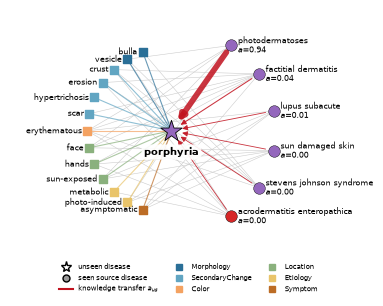

In [22]:
# case 1: transfer subgraph
if len(picked) > 0:
    transfer_subgraph(yu[picked[0]], 'figKG3_case1_transfer_graph')

saved figures_v2b\fig8_case1_prediction.pdf


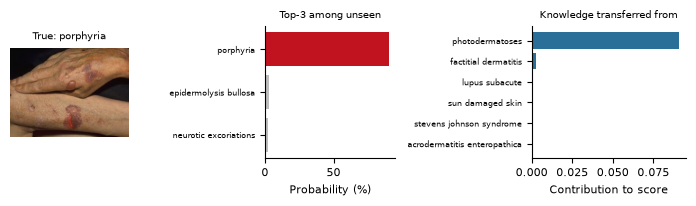

In [23]:
# case 1: prediction panel
if len(picked) > 0:
    prediction_panel(picked[0], 'fig8_case1_prediction')

saved figures_v2b\figKG3_case2_transfer_graph.pdf


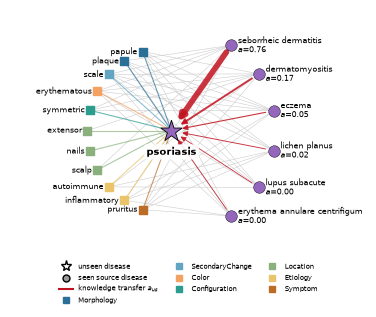

In [24]:
# case 2: transfer subgraph
if len(picked) > 1:
    transfer_subgraph(yu[picked[1]], 'figKG3_case2_transfer_graph')

saved figures_v2b\fig8_case2_prediction.pdf


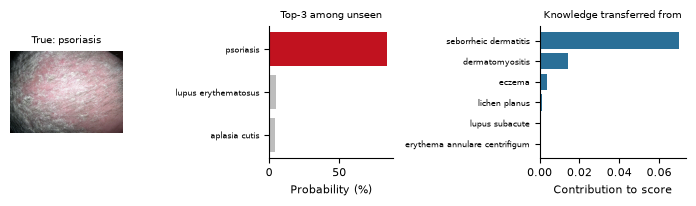

In [25]:
# case 2: prediction panel
if len(picked) > 1:
    prediction_panel(picked[1], 'fig8_case2_prediction')

saved figures_v2b\figKG3_case3_transfer_graph.pdf


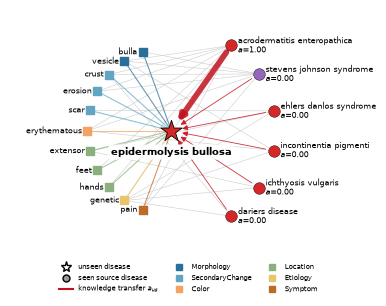

In [26]:
# case 3: transfer subgraph
if len(picked) > 2:
    transfer_subgraph(yu[picked[2]], 'figKG3_case3_transfer_graph')

saved figures_v2b\fig8_case3_prediction.pdf


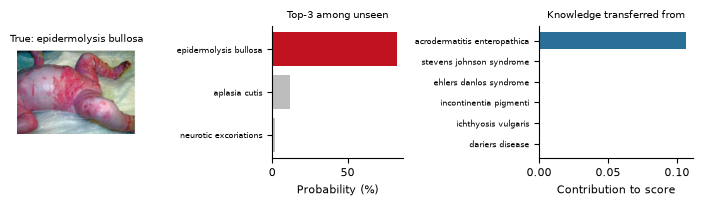

In [27]:
# case 3: prediction panel
if len(picked) > 2:
    prediction_panel(picked[2], 'fig8_case3_prediction')

In [28]:
from scipy.stats import ttest_rel
def paired(a, b, col='zsl_bacc'):
    A = Z[Z['method'] == a].set_index('split')[col]; B = Z[Z['method'] == b].set_index('split')[col]
    d = (A - B.reindex(A.index)) * 100
    print(f'{a} - {b} [{col}]: {d.mean():+.2f} pp (paired std {d.std():.2f}), '
          f'better in {(d > 0).sum()}/{len(d)} splits, p = {ttest_rel(A, B.reindex(A.index)).pvalue:.3f}')

paired('zs_full', 'zs_name')
paired('ours', 'residual')
paired('ours', 'ours_shuffled')
paired('ours', 'residual', 'gzsl_h')

zs_full - zs_name [zsl_bacc]: +1.57 pp (paired std 3.29), better in 3/5 splits, p = 0.346
ours - residual [zsl_bacc]: +0.30 pp (paired std 0.93), better in 3/5 splits, p = 0.508
ours - ours_shuffled [zsl_bacc]: +2.60 pp (paired std 1.36), better in 5/5 splits, p = 0.013
ours - residual [gzsl_h]: -0.21 pp (paired std 2.12), better in 3/5 splits, p = 0.832
